# Multi-Category Product Recognition: CNN + OCR + Supabase

Recognizes individual products across five categories: **Biscuits, Chips, Stationery, Electronics, and Toiletries**. The notebook collects candidate images, trains one EfficientNetB0 classifier, uses OCR as an additional product-name signal, and provides a Gradio upload/webcam interface connected to Supabase inventory.

**Important:** image-search results are candidate images, not a verified dataset. Review each class folder and remove incorrect, duplicate, or irrelevant images before training. Test the trained model with new phone photos. Keep Supabase credentials in Colab Secrets; never hardcode keys in a public notebook.

**No barcode recognition is included** in this notebook.

## 1. Install dependencies

In [1]:
!pip -q install -U tensorflow gradio supabase easyocr ddgs opencv-python-headless scikit-learn pandas pillow requests rapidfuzz

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 79.5/79.5 kB 3.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 31.4/31.4 MB 56.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 64.5/64.5 kB 3.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 48.5/48.5 kB 2.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.9/2.9 MB 76.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 47.6/47.6 kB 2.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.1/9.1 MB 98.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.8/10.8 MB 93.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 6.9/6.9 MB 95.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 73.1/73.1 kB 4.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.2/3.2 MB 83.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 6.6/6.6 MB 91.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 183.4/183.4 kB 12.3 M

## 2. Imports

In [2]:
import os, re, io, json, time, random, hashlib
from pathlib import Path
from datetime import datetime, timezone
import numpy as np, pandas as pd, requests
from PIL import Image, ImageFile
ImageFile.LOAD_TRUNCATED_IMAGES = True
import tensorflow as tf
from tensorflow.keras import layers, models
from tensorflow.keras.applications import EfficientNetB0
from tensorflow.keras.applications.efficientnet import preprocess_input
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report
import matplotlib.pyplot as plt
SEED=42
random.seed(SEED); np.random.seed(SEED); tf.random.set_seed(SEED)
print(tf.__version__, tf.config.list_physical_devices('GPU'))

2.21.0 []


## 3. Define 50 individual products across five categories

This starter catalog includes 10 products in each category: Biscuits, Chips, Stationery, Electronics, and Toiletries. You can add or remove products by editing `PRODUCTS`. Each product key becomes a separate CNN class.

In [3]:
PRODUCTS = {'oreo': {'product_name': 'Oreo Original Biscuits',
          'brand': 'Oreo',
          'category': 'Biscuits',
          'search': ['Oreo original biscuit packet front',
                     'Oreo biscuits blue packet product image'],
          'aliases': ['oreo', 'oreo original']},
 'parle_g': {'product_name': 'Parle-G Biscuits',
             'brand': 'Parle',
             'category': 'Biscuits',
             'search': ['Parle G glucose biscuits yellow packet front',
                        'Parle-G biscuit packet product image'],
             'aliases': ['parle g', 'parle-g']},
 'hide_seek': {'product_name': 'Parle Hide & Seek Biscuits',
               'brand': 'Parle',
               'category': 'Biscuits',
               'search': ['Parle Hide and Seek chocolate chip biscuit packet front'],
               'aliases': ['hide and seek', 'hide & seek', 'hide seek']},
 'good_day': {'product_name': 'Britannia Good Day Biscuits',
              'brand': 'Britannia',
              'category': 'Biscuits',
              'search': ['Britannia Good Day biscuits packet front'],
              'aliases': ['good day', 'britannia good day']},
 'bourbon': {'product_name': 'Britannia Bourbon Biscuits',
             'brand': 'Britannia',
             'category': 'Biscuits',
             'search': ['Britannia bourbon cream biscuits packet front'],
             'aliases': ['bourbon', 'britannia bourbon']},
 'marie_gold': {'product_name': 'Britannia Marie Gold Biscuits',
                'brand': 'Britannia',
                'category': 'Biscuits',
                'search': ['Britannia Marie Gold biscuit packet front'],
                'aliases': ['marie gold', 'britannia marie']},
 'monaco': {'product_name': 'Parle Monaco Biscuits',
            'brand': 'Parle',
            'category': 'Biscuits',
            'search': ['Parle Monaco salted crackers packet front'],
            'aliases': ['monaco', 'parle monaco']},
 '50_50': {'product_name': 'Britannia 50-50 Biscuits',
           'brand': 'Britannia',
           'category': 'Biscuits',
           'search': ['Britannia 50 50 biscuits packet front'],
           'aliases': ['50 50', '50-50', 'fifty fifty']},
 'jim_jam': {'product_name': 'Britannia Jim Jam Biscuits',
             'brand': 'Britannia',
             'category': 'Biscuits',
             'search': ['Britannia Jim Jam biscuits packet front'],
             'aliases': ['jim jam', 'britannia jim jam']},
 'dark_fantasy': {'product_name': 'Sunfeast Dark Fantasy Biscuits',
                  'brand': 'Sunfeast',
                  'category': 'Biscuits',
                  'search': ['Sunfeast Dark Fantasy choco fills biscuit packet front'],
                  'aliases': ['dark fantasy', 'sunfeast dark fantasy']},
 'lays_classic': {'product_name': "Lay's Classic Salted Chips",
                  'brand': "Lay's",
                  'category': 'Chips',
                  'search': ['Lays classic salted chips packet front'],
                  'aliases': ['lays classic', 'lays salted']},
 'lays_magic_masala': {'product_name': "Lay's Magic Masala Chips",
                       'brand': "Lay's",
                       'category': 'Chips',
                       'search': ['Lays magic masala chips packet front'],
                       'aliases': ['lays magic masala', 'magic masala lays']},
 'kurkure_masala': {'product_name': 'Kurkure Masala Munch',
                    'brand': 'Kurkure',
                    'category': 'Chips',
                    'search': ['Kurkure masala munch packet front'],
                    'aliases': ['kurkure', 'masala munch']},
 'bingo_mad_angles': {'product_name': 'Bingo Mad Angles',
                      'brand': 'Bingo',
                      'category': 'Chips',
                      'search': ['Bingo mad angles chips packet front'],
                      'aliases': ['mad angles', 'bingo mad angles']},
 'doritos_nachos': {'product_name': 'Doritos Nacho Chips',
                    'brand': 'Doritos',
                    'category': 'Chips',
                    'search': ['Doritos nacho cheese chips packet front'],
                    'aliases': ['doritos', 'doritos nachos']},
 'pringles_original': {'product_name': 'Pringles Original Chips',
                       'brand': 'Pringles',
                       'category': 'Chips',
                       'search': ['Pringles original potato crisps can product front'],
                       'aliases': ['pringles', 'pringles original']},
 'uncle_chips_spicy': {'product_name': 'Uncle Chipps Spicy Treat',
                       'brand': 'Uncle Chipps',
                       'category': 'Chips',
                       'search': ['Uncle Chipps spicy treat packet front'],
                       'aliases': ['uncle chipps', 'spicy treat']},
 'bingo_tedhe_medhe': {'product_name': 'Bingo Tedhe Medhe',
                       'brand': 'Bingo',
                       'category': 'Chips',
                       'search': ['Bingo tedhe medhe packet front'],
                       'aliases': ['tedhe medhe', 'bingo tedhe medhe']},
 'haldirams_aloo_bhujia': {'product_name': "Haldiram's Aloo Bhujia",
                           'brand': "Haldiram's",
                           'category': 'Chips',
                           'search': ['Haldirams aloo bhujia packet front'],
                           'aliases': ['aloo bhujia', 'haldiram bhujia']},
 'too_yumm_multigrain': {'product_name': 'Too Yumm Multigrain Chips',
                         'brand': 'Too Yumm',
                         'category': 'Chips',
                         'search': ['Too Yumm multigrain chips packet front'],
                         'aliases': ['too yumm', 'too yumm chips']},
 'classmate_notebook': {'product_name': 'Classmate Notebook',
                        'brand': 'Classmate',
                        'category': 'Stationery',
                        'search': ['Classmate notebook product cover'],
                        'aliases': ['classmate notebook', 'classmate']},
 'reynolds_ball_pen': {'product_name': 'Reynolds Ball Pen',
                       'brand': 'Reynolds',
                       'category': 'Stationery',
                       'search': ['Reynolds ball pen product image'],
                       'aliases': ['reynolds pen', 'reynolds ball pen']},
 'cello_gripper_pen': {'product_name': 'Cello Gripper Ball Pen',
                       'brand': 'Cello',
                       'category': 'Stationery',
                       'search': ['Cello gripper ball pen product image'],
                       'aliases': ['cello gripper', 'cello pen']},
 'apsara_pencil': {'product_name': 'Apsara Pencils',
                   'brand': 'Apsara',
                   'category': 'Stationery',
                   'search': ['Apsara pencil pack product image'],
                   'aliases': ['apsara pencil', 'apsara pencils']},
 'nataraj_pencil': {'product_name': 'Nataraj Pencils',
                    'brand': 'Nataraj',
                    'category': 'Stationery',
                    'search': ['Nataraj pencil pack product image'],
                    'aliases': ['nataraj pencil', 'nataraj pencils']},
 'camlin_markers': {'product_name': 'Camlin Colour Markers',
                    'brand': 'Camlin',
                    'category': 'Stationery',
                    'search': ['Camlin colour marker set product image'],
                    'aliases': ['camlin markers', 'camlin colour markers']},
 'fevicol_mr': {'product_name': 'Fevicol MR Glue',
                'brand': 'Fevicol',
                'category': 'Stationery',
                'search': ['Fevicol MR glue bottle product image'],
                'aliases': ['fevicol mr', 'fevicol glue']},
 'classmate_eraser': {'product_name': 'Classmate Eraser',
                      'brand': 'Classmate',
                      'category': 'Stationery',
                      'search': ['Classmate eraser product image'],
                      'aliases': ['classmate eraser', 'eraser']},
 'camlin_scale': {'product_name': 'Camlin 30 cm Ruler',
                  'brand': 'Camlin',
                  'category': 'Stationery',
                  'search': ['Camlin 30 cm ruler product image'],
                  'aliases': ['camlin ruler', '30 cm scale']},
 'logitech_mouse': {'product_name': 'Logitech Computer Mouse',
                    'brand': 'Logitech',
                    'category': 'Electronics',
                    'search': ['Logitech computer mouse product image'],
                    'aliases': ['logitech mouse', 'computer mouse']},
 'logitech_keyboard': {'product_name': 'Logitech Keyboard',
                       'brand': 'Logitech',
                       'category': 'Electronics',
                       'search': ['Logitech keyboard product image'],
                       'aliases': ['logitech keyboard', 'computer keyboard']},
 'sandisk_usb': {'product_name': 'SanDisk USB Flash Drive',
                 'brand': 'SanDisk',
                 'category': 'Electronics',
                 'search': ['SanDisk USB flash drive product image'],
                 'aliases': ['sandisk usb', 'pendrive']},
 'samsung_charger': {'product_name': 'Samsung Phone Charger',
                     'brand': 'Samsung',
                     'category': 'Electronics',
                     'search': ['Samsung phone charger adapter product image'],
                     'aliases': ['samsung charger', 'phone charger']},
 'boat_earphones': {'product_name': 'boAt Wired Earphones',
                    'brand': 'boAt',
                    'category': 'Electronics',
                    'search': ['boAt wired earphones product image'],
                    'aliases': ['boat earphones', 'boat wired earphones']},
 'jbl_headphones': {'product_name': 'JBL Headphones',
                    'brand': 'JBL',
                    'category': 'Electronics',
                    'search': ['JBL headphones product image'],
                    'aliases': ['jbl headphones', 'jbl headset']},
 'duracell_battery': {'product_name': 'Duracell AA Batteries',
                      'brand': 'Duracell',
                      'category': 'Electronics',
                      'search': ['Duracell AA battery pack product image'],
                      'aliases': ['duracell battery', 'aa batteries']},
 'canon_calculator': {'product_name': 'Canon Calculator',
                      'brand': 'Canon',
                      'category': 'Electronics',
                      'search': ['Canon calculator product image'],
                      'aliases': ['canon calculator', 'calculator']},
 'tp_link_router': {'product_name': 'TP-Link WiFi Router',
                    'brand': 'TP-Link',
                    'category': 'Electronics',
                    'search': ['TP Link wifi router product image'],
                    'aliases': ['tp link router', 'wifi router']},
 'anker_powerbank': {'product_name': 'Anker Power Bank',
                     'brand': 'Anker',
                     'category': 'Electronics',
                     'search': ['Anker power bank product image'],
                     'aliases': ['anker power bank', 'powerbank']},
 'dove_soap': {'product_name': 'Dove Beauty Bar',
               'brand': 'Dove',
               'category': 'Toiletries',
               'search': ['Dove beauty bar soap package front'],
               'aliases': ['dove soap', 'dove beauty bar']},
 'colgate_toothpaste': {'product_name': 'Colgate Toothpaste',
                        'brand': 'Colgate',
                        'category': 'Toiletries',
                        'search': ['Colgate toothpaste tube product image'],
                        'aliases': ['colgate toothpaste', 'colgate']},
 'head_shoulders': {'product_name': 'Head & Shoulders Shampoo',
                    'brand': 'Head & Shoulders',
                    'category': 'Toiletries',
                    'search': ['Head and Shoulders shampoo bottle product image'],
                    'aliases': ['head shoulders', 'head and shoulders shampoo']},
 'clinic_plus': {'product_name': 'Clinic Plus Shampoo',
                 'brand': 'Clinic Plus',
                 'category': 'Toiletries',
                 'search': ['Clinic Plus shampoo bottle product image'],
                 'aliases': ['clinic plus shampoo', 'clinic plus']},
 'lifebuoy_handwash': {'product_name': 'Lifebuoy Handwash',
                       'brand': 'Lifebuoy',
                       'category': 'Toiletries',
                       'search': ['Lifebuoy handwash bottle product image'],
                       'aliases': ['lifebuoy handwash', 'lifebuoy']},
 'ponds_cold_cream': {'product_name': "Pond's Cold Cream",
                      'brand': "Pond's",
                      'category': 'Toiletries',
                      'search': ['Ponds cold cream jar product image'],
                      'aliases': ['ponds cream', 'ponds cold cream']},
 'vaseline_lotion': {'product_name': 'Vaseline Body Lotion',
                     'brand': 'Vaseline',
                     'category': 'Toiletries',
                     'search': ['Vaseline body lotion bottle product image'],
                     'aliases': ['vaseline lotion', 'vaseline body lotion']},
 'nivea_deodorant': {'product_name': 'Nivea Deodorant',
                     'brand': 'Nivea',
                     'category': 'Toiletries',
                     'search': ['Nivea deodorant can product image'],
                     'aliases': ['nivea deodorant', 'nivea deo']},
 'sensodyne_toothpaste': {'product_name': 'Sensodyne Toothpaste',
                          'brand': 'Sensodyne',
                          'category': 'Toiletries',
                          'search': ['Sensodyne toothpaste tube product image'],
                          'aliases': ['sensodyne toothpaste', 'sensodyne']},
 'detol_liquid': {'product_name': 'Dettol Antiseptic Liquid',
                  'brand': 'Dettol',
                  'category': 'Toiletries',
                  'search': ['Dettol antiseptic liquid bottle product image'],
                  'aliases': ['dettol liquid', 'dettol antiseptic']},
 'kokuyo_stapler': {'product_name': 'Kokuyo Stapler',
                    'brand': 'Kokuyo',
                    'category': 'Stationery',
                    'search': ['Kokuyo stapler product image'],
                    'aliases': ['kokuyo stapler', 'stapler']}}

CLASS_NAMES = list(PRODUCTS)
DATA_DIR = Path('/content/product_level_dataset')
DATA_DIR.mkdir(parents=True, exist_ok=True)

print("Total individual products:", len(CLASS_NAMES))
print(pd.DataFrame([
    {"class_key": key, "product_name": value["product_name"], "category": value["category"]}
    for key, value in PRODUCTS.items()
]).groupby("category").size().rename("products_per_category"))

Total individual products: 50
category
Biscuits       10
Chips          10
Electronics    10
Stationery     10
Toiletries     10
Name: products_per_category, dtype: int64


## 4. Download candidate images from online image search

This uses the `ddgs` image search package. It attempts to collect images for every product in `PRODUCTS`. Some websites block downloads and search results can be irrelevant, so inspect each class folder before training. For a first run, the notebook targets up to 30 candidate images per product to keep download size manageable.

In [4]:
from ddgs import DDGS

def download_candidates(class_key, max_images=30, results_per_query=30):
    out = DATA_DIR / class_key
    out.mkdir(parents=True, exist_ok=True)
    saved = len(list(out.glob('*.jpg')))
    hashes = set()
    for f in out.glob('*'):
        try:
            hashes.add(hashlib.md5(f.read_bytes()).hexdigest())
        except Exception:
            pass

    for query in PRODUCTS[class_key]['search']:
        if saved >= max_images:
            break
        try:
            with DDGS() as ddgs:
                results = list(ddgs.images(query, max_results=results_per_query))
        except Exception as e:
            print('Search error:', query, e)
            continue

        for item in results:
            if saved >= max_images:
                break
            url = item.get('image') or item.get('thumbnail')
            if not url:
                continue
            try:
                response = requests.get(
                    url, timeout=12,
                    headers={'User-Agent': 'Mozilla/5.0'}
                )
                if response.status_code != 200:
                    continue
                digest = hashlib.md5(response.content).hexdigest()
                if digest in hashes:
                    continue
                im = Image.open(io.BytesIO(response.content)).convert('RGB')
                if min(im.size) < 80:
                    continue
                im.thumbnail((1200, 1200))
                im.save(out / f'{class_key}_{saved:04d}.jpg', 'JPEG', quality=92)
                hashes.add(digest)
                saved += 1
            except Exception:
                continue

    print(f'{class_key}: {saved} images')


# Run for all 50 product classes. This may take several minutes.
for key in CLASS_NAMES:
    download_candidates(key, max_images=30)

oreo: 30 images


/usr/local/lib/python3.13/dist-packages/PIL/Image.py:1047: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  this passes the operation to :py:meth:`~PIL.Image.Image.quantize`,


parle_g: 30 images
hide_seek: 27 images
good_day: 29 images
bourbon: 28 images
marie_gold: 29 images
monaco: 28 images
50_50: 29 images
jim_jam: 29 images
dark_fantasy: 21 images
lays_classic: 26 images
lays_magic_masala: 27 images
kurkure_masala: 29 images
bingo_mad_angles: 26 images
doritos_nachos: 28 images
pringles_original: 29 images
uncle_chips_spicy: 25 images
bingo_tedhe_medhe: 28 images
haldirams_aloo_bhujia: 28 images
too_yumm_multigrain: 28 images
classmate_notebook: 27 images
reynolds_ball_pen: 30 images
cello_gripper_pen: 28 images
apsara_pencil: 30 images
nataraj_pencil: 25 images
camlin_markers: 29 images
fevicol_mr: 24 images
classmate_eraser: 27 images
camlin_scale: 29 images
logitech_mouse: 28 images
logitech_keyboard: 27 images
sandisk_usb: 27 images
samsung_charger: 30 images
boat_earphones: 28 images
jbl_headphones: 28 images
duracell_battery: 25 images
canon_calculator: 29 images
tp_link_router: 26 images
anker_powerbank: 28 images
dove_soap: 30 images
colgate_too

## 5. Review dataset quality
Run this for each class. Delete images that are the wrong product, collages, logos, tiny thumbnails, or duplicates.

oreo count: 30


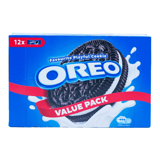

oreo_0019.jpg


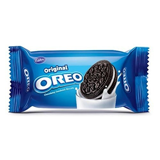

oreo_0029.jpg


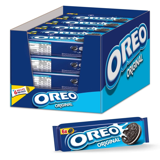

oreo_0006.jpg


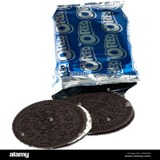

oreo_0025.jpg


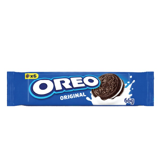

oreo_0014.jpg


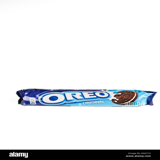

oreo_0022.jpg


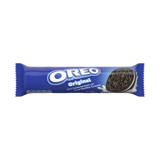

oreo_0003.jpg


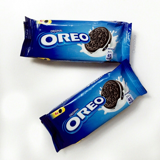

oreo_0015.jpg


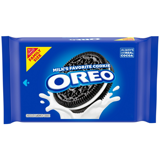

oreo_0028.jpg


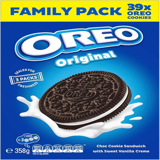

oreo_0013.jpg


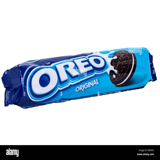

oreo_0016.jpg


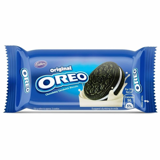

oreo_0012.jpg


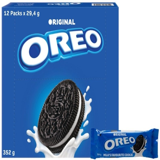

oreo_0008.jpg


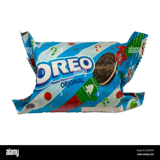

oreo_0020.jpg


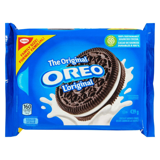

oreo_0000.jpg


In [5]:
from IPython.display import display
def show_samples(class_key, n=15):
    files=list((DATA_DIR/class_key).glob('*.jpg'))
    print(class_key, 'count:', len(files))
    for f in files[:n]:
        try:
            display(Image.open(f).convert('RGB').resize((160,160)))
            print(f.name)
        except: pass
show_samples('oreo')

## 6. Prepare train/validation/test splits

Review the downloaded folders before this step. Aim for at least 20–30 valid images per product, ideally more. Classes with fewer than 5 valid images are excluded from training; any excluded product will not be recognized by the trained CNN until its dataset is improved and the model is retrained. Test with new phone photos too.

In [6]:
records=[]
for key in CLASS_NAMES:
    for p in (DATA_DIR/key).glob('*'):
        if p.suffix.lower() not in {'.jpg','.jpeg','.png','.webp'}: continue
        try:
            with Image.open(p) as im: im.verify()
            records.append({'path':str(p),'label':key})
        except: pass
df=pd.DataFrame(records)
display(df.groupby('label').size().rename('images').to_frame())
counts=df.label.value_counts()
class_names=sorted([c for c in CLASS_NAMES if counts.get(c,0)>=5])
df=df[df.label.isin(class_names)].copy()
if len(class_names)<2: raise RuntimeError('Need at least two classes with 5+ images.')
train_parts=[]; val_parts=[]; test_parts=[]
for label, part in df.groupby('label'):
    train_p, temp=train_test_split(part, test_size=.30, random_state=SEED)
    val_p, test_p=train_test_split(temp, test_size=.50, random_state=SEED)
    train_parts.append(train_p); val_parts.append(val_p); test_parts.append(test_p)
train_df=pd.concat(train_parts).reset_index(drop=True)
val_df=pd.concat(val_parts).reset_index(drop=True)
test_df=pd.concat(test_parts).reset_index(drop=True)
class_to_idx={c:i for i,c in enumerate(class_names)}
print('Classes:',class_names,'\nTrain/val/test:',len(train_df),len(val_df),len(test_df))

,images
label,
50_50,29
anker_powerbank,28
apsara_pencil,30
bingo_mad_angles,26
bingo_tedhe_medhe,28
boat_earphones,28
bourbon,28
camlin_markers,29
camlin_scale,29


Classes: ['50_50', 'anker_powerbank', 'apsara_pencil', 'bingo_mad_angles', 'bingo_tedhe_medhe', 'boat_earphones', 'bourbon', 'camlin_markers', 'camlin_scale', 'canon_calculator', 'cello_gripper_pen', 'classmate_eraser', 'classmate_notebook', 'clinic_plus', 'colgate_toothpaste', 'dark_fantasy', 'detol_liquid', 'doritos_nachos', 'dove_soap', 'duracell_battery', 'fevicol_mr', 'good_day', 'haldirams_aloo_bhujia', 'head_shoulders', 'hide_seek', 'jbl_headphones', 'jim_jam', 'kokuyo_stapler', 'kurkure_masala', 'lays_classic', 'lays_magic_masala', 'lifebuoy_handwash', 'logitech_keyboard', 'logitech_mouse', 'marie_gold', 'monaco', 'nataraj_pencil', 'nivea_deodorant', 'oreo', 'parle_g', 'ponds_cold_cream', 'pringles_original', 'reynolds_ball_pen', 'samsung_charger', 'sandisk_usb', 'sensodyne_toothpaste', 'too_yumm_multigrain', 'tp_link_router', 'uncle_chips_spicy', 'vaseline_lotion'] 
Train/val/test: 946 199 239


## 7. Train EfficientNetB0 on all available product classes

In [7]:
IMG_SIZE=(224,224); BATCH_SIZE=16; AUTOTUNE=tf.data.AUTOTUNE
def load_image(path,label):
    raw=tf.io.read_file(path)
    img=tf.image.decode_image(raw,channels=3,expand_animations=False)
    img.set_shape([None,None,3])
    img=tf.image.resize(img,IMG_SIZE)
    img=preprocess_input(img)
    return img, tf.one_hot(label,depth=len(class_names))
def make_ds(frame, training=False):
    ds=tf.data.Dataset.from_tensor_slices((frame.path.values,frame.label.map(class_to_idx).values.astype('int32')))
    if training: ds=ds.shuffle(len(frame),seed=SEED)
    return ds.map(load_image,num_parallel_calls=AUTOTUNE).batch(BATCH_SIZE).prefetch(AUTOTUNE)
train_ds=make_ds(train_df,True); val_ds=make_ds(val_df); test_ds=make_ds(test_df)
base=EfficientNetB0(include_top=False,weights='imagenet',input_shape=(224,224,3))
base.trainable=False
inputs=layers.Input(shape=(224,224,3))
x=base(inputs,training=False)
x=layers.GlobalAveragePooling2D()(x)
x=layers.Dropout(.3)(x)
outputs=layers.Dense(len(class_names),activation='softmax')(x)
model=models.Model(inputs,outputs)
model.compile(optimizer=tf.keras.optimizers.Adam(1e-3),loss='categorical_crossentropy',metrics=['accuracy'])
callbacks=[tf.keras.callbacks.EarlyStopping(monitor='val_loss',patience=3,restore_best_weights=True)]
history=model.fit(train_ds,validation_data=val_ds,epochs=5,callbacks=callbacks)

16705208/16705208 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Epoch 1/8
60/60 ━━━━━━━━━━━━━━━━━━━━ 106s 2s/step - accuracy: 0.3182 - loss: 2.9731 - val_accuracy: 0.7940 - val_loss: 1.6954
Epoch 2/8
60/60 ━━━━━━━━━━━━━━━━━━━━ 142s 2s/step - accuracy: 0.8340 - loss: 1.2244 - val_accuracy: 0.8894 - val_loss: 0.9286
Epoch 3/8
60/60 ━━━━━━━━━━━━━━━━━━━━ 133s 1s/step - accuracy: 0.9292 - loss: 0.6841 - val_accuracy: 0.9146 - val_loss: 0.6513
Epoch 4/8
60/60 ━━━━━━━━━━━━━━━━━━━━ 91s 2s/step - accuracy: 0.9419 - loss: 0.4544 - val_accuracy: 0.9146 - val_loss: 0.5169
Epoch 5/8
60/60 ━━━━━━━━━━━━━━━━━━━━ 131s 1s/step - accuracy: 0.9672 - loss: 0.3357 - val_accuracy: 0.9347 - val_loss: 0.4289
Epoch 6/8
60/60 ━━━━━━━━━━━━━━━━━━━━ 90s 1s/step - accuracy: 0.9820 - loss: 0.2431 - val_accuracy: 0.9347 - val_loss: 0.3806
Epoch 7/8
60/60 ━━━━━━━━━━━━━━━━━━━━ 88s 1s/step - accuracy: 0.9915 - loss: 0.1857 - val_accuracy: 0.9347 - val_loss: 0.3429
Epoch 8/8
60/60 ━━━━━━━━━━━━━━━━━━━━ 82s 1s/step - accuracy: 0.9958 - 

## 8. Plot accuracy/loss and evaluate

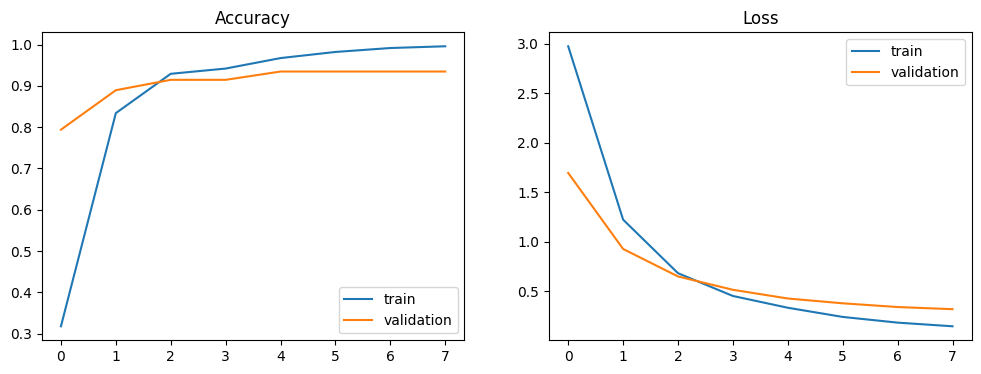

                       precision    recall  f1-score   support

                50_50       0.83      1.00      0.91         5
      anker_powerbank       0.83      1.00      0.91         5
        apsara_pencil       0.71      1.00      0.83         5
     bingo_mad_angles       1.00      1.00      1.00         4
    bingo_tedhe_medhe       1.00      1.00      1.00         5
       boat_earphones       1.00      1.00      1.00         5
              bourbon       1.00      1.00      1.00         5
       camlin_markers       1.00      0.80      0.89         5
         camlin_scale       1.00      1.00      1.00         5
     canon_calculator       1.00      1.00      1.00         5
    cello_gripper_pen       1.00      1.00      1.00         5
     classmate_eraser       1.00      0.80      0.89         5
   classmate_notebook       1.00      1.00      1.00         5
          clinic_plus       1.00      1.00      1.00         5
   colgate_toothpaste       1.00      0.75      0.86  

In [8]:
plt.figure(figsize=(12,4))
plt.subplot(1,2,1); plt.plot(history.history['accuracy'],label='train'); plt.plot(history.history['val_accuracy'],label='validation'); plt.title('Accuracy'); plt.legend()
plt.subplot(1,2,2); plt.plot(history.history['loss'],label='train'); plt.plot(history.history['val_loss'],label='validation'); plt.title('Loss'); plt.legend()
plt.show()
y_true=test_df.label.map(class_to_idx).to_numpy()
y_prob=model.predict(test_ds,verbose=0)
y_pred=y_prob.argmax(axis=1)
print(classification_report(y_true,y_pred,labels=list(range(len(class_names))),target_names=class_names,zero_division=0))

## 9. Save model and label order

In [9]:
MODEL_PATH='/content/product_level_efficientnet.keras'
model.save(MODEL_PATH)
with open('/content/class_names.json','w') as f:
    json.dump({'class_names':class_names,'products':PRODUCTS},f,indent=2)
print('Saved',MODEL_PATH)

Saved /content/product_level_efficientnet.keras


## 10. Supabase credentials

Add `SUPABASE_URL` and `SUPABASE_KEY` in the Google Colab **Secrets** panel. Never hardcode keys in a public notebook. The key must have permission to read/write the `inventory` and `recognition_logs` tables.

In [12]:
from google.colab import userdata
try:
    SUPABASE_URL = userdata.get('SUPABASE_URL')
    SUPABASE_KEY = userdata.get('SUPABASE_KEY')
except Exception as e:
    print(f"Could not fetch secrets: {e}")
    SUPABASE_URL = None
    SUPABASE_KEY = None

if not SUPABASE_URL or not SUPABASE_KEY:
    print('Add SUPABASE_URL and SUPABASE_KEY in Colab Secrets (left sidebar), grant access, then rerun.')
    supabase = None
else:
    from supabase import create_client
    supabase = create_client(SUPABASE_URL, SUPABASE_KEY)
    print('Supabase ready')

Supabase ready


## 11. Supabase SQL setup

Run this SQL in Supabase SQL Editor. It prepares the inventory and recognition-log columns used by this notebook, plus a product catalog containing all 50 product definitions. Barcode recognition is not included.

Run the following SQL in **Supabase → SQL Editor** (do not run it as a Python cell):

```sql
ALTER TABLE public.inventory ADD COLUMN IF NOT EXISTS category TEXT;
ALTER TABLE public.inventory ALTER COLUMN "timestamp" SET DEFAULT NOW();
ALTER TABLE public.inventory ALTER COLUMN quantity SET DEFAULT 0;

CREATE TABLE IF NOT EXISTS public.product_catalog (
  id BIGSERIAL PRIMARY KEY,
  product_name TEXT NOT NULL UNIQUE,
  brand TEXT,
  category TEXT NOT NULL,
  aliases TEXT[] NOT NULL DEFAULT '{}'
);

CREATE TABLE IF NOT EXISTS public.recognition_logs (
  id BIGSERIAL PRIMARY KEY,
  product_name TEXT,
  category TEXT,
  confidence DOUBLE PRECISION,
  method TEXT,
  ocr_text TEXT,
  created_at TIMESTAMPTZ NOT NULL DEFAULT NOW()
);

ALTER TABLE public.recognition_logs ADD COLUMN IF NOT EXISTS method TEXT;
ALTER TABLE public.recognition_logs ADD COLUMN IF NOT EXISTS ocr_text TEXT;
ALTER TABLE public.recognition_logs ADD COLUMN IF NOT EXISTS created_at TIMESTAMPTZ NOT NULL DEFAULT NOW();

INSERT INTO public.product_catalog (product_name, brand, category, aliases) VALUES
('Oreo Original Biscuits', 'Oreo', 'Biscuits', ARRAY['oreo', 'oreo original']::TEXT[]),
('Parle-G Biscuits', 'Parle', 'Biscuits', ARRAY['parle g', 'parle-g']::TEXT[]),
('Parle Hide & Seek Biscuits', 'Parle', 'Biscuits', ARRAY['hide and seek', 'hide & seek', 'hide seek']::TEXT[]),
('Britannia Good Day Biscuits', 'Britannia', 'Biscuits', ARRAY['good day', 'britannia good day']::TEXT[]),
('Britannia Bourbon Biscuits', 'Britannia', 'Biscuits', ARRAY['bourbon', 'britannia bourbon']::TEXT[]),
('Britannia Marie Gold Biscuits', 'Britannia', 'Biscuits', ARRAY['marie gold', 'britannia marie']::TEXT[]),
('Parle Monaco Biscuits', 'Parle', 'Biscuits', ARRAY['monaco', 'parle monaco']::TEXT[]),
('Britannia 50-50 Biscuits', 'Britannia', 'Biscuits', ARRAY['50 50', '50-50', 'fifty fifty']::TEXT[]),
('Britannia Jim Jam Biscuits', 'Britannia', 'Biscuits', ARRAY['jim jam', 'britannia jim jam']::TEXT[]),
('Sunfeast Dark Fantasy Biscuits', 'Sunfeast', 'Biscuits', ARRAY['dark fantasy', 'sunfeast dark fantasy']::TEXT[]),
('Lay''s Classic Salted Chips', 'Lay''s', 'Chips', ARRAY['lays classic', 'lays salted']::TEXT[]),
('Lay''s Magic Masala Chips', 'Lay''s', 'Chips', ARRAY['lays magic masala', 'magic masala lays']::TEXT[]),
('Kurkure Masala Munch', 'Kurkure', 'Chips', ARRAY['kurkure', 'masala munch']::TEXT[]),
('Bingo Mad Angles', 'Bingo', 'Chips', ARRAY['mad angles', 'bingo mad angles']::TEXT[]),
('Doritos Nacho Chips', 'Doritos', 'Chips', ARRAY['doritos', 'doritos nachos']::TEXT[]),
('Pringles Original Chips', 'Pringles', 'Chips', ARRAY['pringles', 'pringles original']::TEXT[]),
('Uncle Chipps Spicy Treat', 'Uncle Chipps', 'Chips', ARRAY['uncle chipps', 'spicy treat']::TEXT[]),
('Bingo Tedhe Medhe', 'Bingo', 'Chips', ARRAY['tedhe medhe', 'bingo tedhe medhe']::TEXT[]),
('Haldiram''s Aloo Bhujia', 'Haldiram''s', 'Chips', ARRAY['aloo bhujia', 'haldiram bhujia']::TEXT[]),
('Too Yumm Multigrain Chips', 'Too Yumm', 'Chips', ARRAY['too yumm', 'too yumm chips']::TEXT[]),
('Classmate Notebook', 'Classmate', 'Stationery', ARRAY['classmate notebook', 'classmate']::TEXT[]),
('Reynolds Ball Pen', 'Reynolds', 'Stationery', ARRAY['reynolds pen', 'reynolds ball pen']::TEXT[]),
('Cello Gripper Ball Pen', 'Cello', 'Stationery', ARRAY['cello gripper', 'cello pen']::TEXT[]),
('Apsara Pencils', 'Apsara', 'Stationery', ARRAY['apsara pencil', 'apsara pencils']::TEXT[]),
('Nataraj Pencils', 'Nataraj', 'Stationery', ARRAY['nataraj pencil', 'nataraj pencils']::TEXT[]),
('Camlin Colour Markers', 'Camlin', 'Stationery', ARRAY['camlin markers', 'camlin colour markers']::TEXT[]),
('Fevicol MR Glue', 'Fevicol', 'Stationery', ARRAY['fevicol mr', 'fevicol glue']::TEXT[]),
('Classmate Eraser', 'Classmate', 'Stationery', ARRAY['classmate eraser', 'eraser']::TEXT[]),
('Camlin 30 cm Ruler', 'Camlin', 'Stationery', ARRAY['camlin ruler', '30 cm scale']::TEXT[]),
('Logitech Computer Mouse', 'Logitech', 'Electronics', ARRAY['logitech mouse', 'computer mouse']::TEXT[]),
('Logitech Keyboard', 'Logitech', 'Electronics', ARRAY['logitech keyboard', 'computer keyboard']::TEXT[]),
('SanDisk USB Flash Drive', 'SanDisk', 'Electronics', ARRAY['sandisk usb', 'pendrive']::TEXT[]),
('Samsung Phone Charger', 'Samsung', 'Electronics', ARRAY['samsung charger', 'phone charger']::TEXT[]),
('boAt Wired Earphones', 'boAt', 'Electronics', ARRAY['boat earphones', 'boat wired earphones']::TEXT[]),
('JBL Headphones', 'JBL', 'Electronics', ARRAY['jbl headphones', 'jbl headset']::TEXT[]),
('Duracell AA Batteries', 'Duracell', 'Electronics', ARRAY['duracell battery', 'aa batteries']::TEXT[]),
('Canon Calculator', 'Canon', 'Electronics', ARRAY['canon calculator', 'calculator']::TEXT[]),
('TP-Link WiFi Router', 'TP-Link', 'Electronics', ARRAY['tp link router', 'wifi router']::TEXT[]),
('Anker Power Bank', 'Anker', 'Electronics', ARRAY['anker power bank', 'powerbank']::TEXT[]),
('Dove Beauty Bar', 'Dove', 'Toiletries', ARRAY['dove soap', 'dove beauty bar']::TEXT[]),
('Colgate Toothpaste', 'Colgate', 'Toiletries', ARRAY['colgate toothpaste', 'colgate']::TEXT[]),
('Head & Shoulders Shampoo', 'Head & Shoulders', 'Toiletries', ARRAY['head shoulders', 'head and shoulders shampoo']::TEXT[]),
('Clinic Plus Shampoo', 'Clinic Plus', 'Toiletries', ARRAY['clinic plus shampoo', 'clinic plus']::TEXT[]),
('Lifebuoy Handwash', 'Lifebuoy', 'Toiletries', ARRAY['lifebuoy handwash', 'lifebuoy']::TEXT[]),
('Pond''s Cold Cream', 'Pond''s', 'Toiletries', ARRAY['ponds cream', 'ponds cold cream']::TEXT[]),
('Vaseline Body Lotion', 'Vaseline', 'Toiletries', ARRAY['vaseline lotion', 'vaseline body lotion']::TEXT[]),
('Nivea Deodorant', 'Nivea', 'Toiletries', ARRAY['nivea deodorant', 'nivea deo']::TEXT[]),
('Sensodyne Toothpaste', 'Sensodyne', 'Toiletries', ARRAY['sensodyne toothpaste', 'sensodyne']::TEXT[]),
('Dettol Antiseptic Liquid', 'Dettol', 'Toiletries', ARRAY['dettol liquid', 'dettol antiseptic']::TEXT[]),
('Kokuyo Stapler', 'Kokuyo', 'Stationery', ARRAY['kokuyo stapler', 'stapler']::TEXT[])
ON CONFLICT (product_name) DO UPDATE
SET brand = EXCLUDED.brand,
    category = EXCLUDED.category,
    aliases = EXCLUDED.aliases;

```

## 12. OCR helper

OCR reads visible text from product packaging and compares it with the names and aliases of classes that are actually present in the trained model. It is an aid to recognition, not a guarantee of correctness.

In [14]:
import sys
import PIL
# Hot-fix for compatibility between Pillow 11.0+ and torchvision typing imports
if not hasattr(PIL, '_typing'):
    import types
    PIL._typing = types.ModuleType("PIL._typing")
    sys.modules["PIL._typing"] = PIL._typing
if not hasattr(PIL._typing, '_Ink'):
    # _Ink is traditionally a tuple of 3 or 4 ints, or a single int/str representing a color
    from typing import Union, Tuple
    PIL._typing._Ink = Union[Tuple[int, int, int], Tuple[int, int, int, int], int, str]
    sys.modules["PIL._typing"]._Ink = PIL._typing._Ink

import re
import numpy as np
import easyocr
from rapidfuzz import fuzz
from datetime import datetime, timezone
import tensorflow as tf

ocr_reader = easyocr.Reader(
    ['en'],
    gpu=bool(tf.config.list_physical_devices('GPU'))
)


def read_ocr_text(pil_image):
    try:
        items = ocr_reader.readtext(
            np.array(pil_image.convert('RGB')),
            detail=1
        )
        return ' '.join(str(item[1]) for item in items)
    except Exception as e:
        print('OCR error:', e)
        return ''


def norm(s):
    return ' '.join(
        re.sub(r'[^a-z0-9]+', ' ', (s or '').lower()).split()
    )


def ocr_match(text):
    hay = norm(text)
    best_key = None
    best_score = 0

    # Only match products represented in the current trained model.
    for key in class_names:
        product = PRODUCTS[key]
        phrases = [product['product_name'], product.get('brand', '')]
        phrases.extend(product.get('aliases', []))

        for phrase in phrases:
            phrase_norm = norm(phrase)
            if not phrase_norm or not hay:
                continue

            score = (
                100 if phrase_norm in hay
                else fuzz.partial_ratio(phrase_norm, hay)
            )

            if score > best_score:
                best_key, best_score = key, score

    if best_key and best_score >= 88:
        return best_key, best_score
    return None

Progress: |██████████████████████████████████████████████████| 100.0% Complete

Progress: |██████████████████████████████████████████████████| 100.0% Complete

## 13. Combined CNN + OCR product identification

In [20]:
import numpy as np
from PIL import Image

# ==========================================
# 1. SETUP / PLACEHOLDER CONFIGURATIONS
# (Ensure these match your actual training/model setup)
# ==========================================
CONFIDENCE_THRESHOLD = 0.70
IMG_SIZE = (224, 224)  # Adjust to your model's expected input size

# Mock examples (Replace these with your actual model, class names, and dictionary)
# model = tf.keras.models.load_model('your_model.h5')
# class_names = [...]
# PRODUCTS = { 'class_key': {'product_name': 'Name', 'category': 'Cat'} }

# def preprocess_input(arr): ...
# def read_ocr_text(image): ...
# def ocr_match(text): ...


# ==========================================
# 2. YOUR CORE FUNCTIONS
# ==========================================
def cnn_predict(image):
    arr = np.asarray(
        image.convert('RGB').resize(IMG_SIZE),
        dtype=np.float32
    )
    arr = preprocess_input(arr)
    probs = model.predict(arr[None, ...], verbose=0)[0]

    indices = np.argsort(probs)[::-1][:5]
    best_index = int(indices[0])

    top = {
        class_names[j]: float(probs[j])
        for j in indices
    }

    return class_names[best_index], float(probs[best_index]), top


def identify_product(image):
    image = image.convert('RGB')
    text = read_ocr_text(image)
    cnn_key, cnn_conf, top = cnn_predict(image)
    ocr_result = ocr_match(text)

    if ocr_result:
        key, ocr_score = ocr_result
        name = PRODUCTS[key]['product_name']
        category = PRODUCTS[key]['category']

        # Keep confidence tied to the CNN when OCR disagrees with it.
        if key == cnn_key:
            conf = max(cnn_conf, min(0.99, ocr_score / 100))
            method = 'cnn+ocr'
        else:
            conf = min(cnn_conf, ocr_score / 100)
            method = 'ocr-assisted (CNN disagrees)'
    elif cnn_conf >= CONFIDENCE_THRESHOLD:
        key = cnn_key
        name = PRODUCTS[key]['product_name']
        category = PRODUCTS[key]['category']
        conf = cnn_conf
        method = 'cnn'
    else:
        name = 'Needs review'
        category = 'Unknown'
        conf = cnn_conf
        method = 'uncertain'

    return {
        'product_name': name,
        'category': category,
        'confidence': float(conf),
        'method': method,
        'ocr_text': text,
        'cnn_guess': PRODUCTS[cnn_key]['product_name'],
        'cnn_confidence': cnn_conf,
        'top5': {
            PRODUCTS[k]['product_name']: v
            for k, v in top.items()
        }
    }


# ==========================================
# 3. TEST / EXECUTION (Generates Colab Output)
# ==========================================
# Uncomment and update the path below once your model and helpers are loaded:
#
# test_image = Image.open('sample_product.jpg')
# result = identify_product(test_image)
# print(result)

## 14. Update inventory and log recognition

The inventory is updated only when you click the Gradio **Add 1 to Inventory** button. If the product already exists, its quantity is increased by one; otherwise, a new row is inserted.

In [22]:
def update_inventory(product_name, category, confidence):
    if supabase is None:
        raise RuntimeError('Supabase not configured')
    if not product_name or product_name == 'Needs review':
        raise ValueError('Low confidence: review the product before adding.')

    existing = (
        supabase.table('inventory')
        .select('id,product,quantity')
        .eq('product', product_name)
        .execute()
        .data or []
    )
    now = datetime.now(timezone.utc).isoformat()

    if existing:
        row = existing[0]
        return (
            supabase.table('inventory')
            .update({
                'quantity': int(row.get('quantity') or 0) + 1,
                'confidence': float(confidence),
                'category': category,
                'timestamp': now
            })
            .eq('id', row['id'])
            .execute()
            .data
        )

    return (
        supabase.table('inventory')
        .insert({
            'product': product_name,
            'confidence': float(confidence),
            'timestamp': now,
            'quantity': 1,
            'category': category
        })
        .execute()
        .data
    )


def log_recognition(result):
    if supabase is None:
        return
    try:
        supabase.table('recognition_logs').insert({
            'product_name': result['product_name'],
            'category': result['category'],
            'confidence': result['confidence'],
            'method': result['method'],
            'ocr_text': result.get('ocr_text', '')[:1000]
        }).execute()
    except Exception as e:
        print('Log insert failed:', e)

## 15. Gradio upload + webcam app

In [23]:
import gradio as gr


def recognize_ui(image):
    if image is None:
        return 'Upload or capture a product image first.', None, {}

    result = identify_product(image)

    # Save the recognition result in Supabase logs
    log_recognition(result)

    output = (
        f"**Product:** {result['product_name']}\n\n"
        f"**Category:** {result['category']}\n\n"
        f"**Method:** {result['method']}\n\n"
        f"**Confidence:** {result['confidence']:.1%}\n\n"
        f"**CNN guess:** {result['cnn_guess']} "
        f"({result['cnn_confidence']:.1%})\n\n"
        f"**OCR text:** "
        f"{result['ocr_text'][:500] or 'No text detected'}"
    )

    return output, result, result['top5']


def add_ui(result):
    if not result:
        return 'Recognize a product first.'

    if result['product_name'] == 'Needs review':
        return (
            'Not added: confidence is low. '
            'Try another photo or review manually.'
        )

    try:
        response = update_inventory(
            result['product_name'],
            result['category'],
            result['confidence']
        )

        return f'Inventory updated successfully: {response}'

    except Exception as e:
        return f'Inventory update failed: {e}'


with gr.Blocks(
    title='CNN Product Recognition & Inventory'
) as demo:

    gr.Markdown('# CNN Product Recognition & Smart Inventory')

    image = gr.Image(
        sources=['upload', 'webcam'],
        type='pil',
        label='Upload or capture product image'
    )

    result_text = gr.Markdown()
    state = gr.State(None)

    top = gr.JSON(label='Top CNN predictions')

    gr.Button(
        'Recognize Product',
        variant='primary'
    ).click(
        recognize_ui,
        inputs=[image],
        outputs=[result_text, state, top]
    )

    gr.Markdown('### Update Supabase Inventory')

    gr.Button('Add 1 to Inventory').click(
        add_ui,
        inputs=[state],
        outputs=[gr.Textbox(label='Inventory status')]
    )

demo.launch(share=True, debug=False)

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://e074411929d952a114.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


## 16. Validation checklist

1. Run the notebook from top to bottom.
2. Inspect every downloaded product folder and remove mislabeled, duplicate, or irrelevant images.
3. Check that every intended product has enough valid images; classes with fewer than 5 images are excluded from training.
4. Review the classification report. High accuracy on web images alone does not guarantee real-world accuracy.
5. Test with new phone photos that were not included in the training dataset.
6. Confirm Supabase logs are written and inventory quantity changes only after clicking the button.
7. Keep uncertain predictions as `Needs review`; do not automatically add them.

**Limits:** This model classifies one main product per image. Multiple products in one frame require object detection or crop detection. Online image search can fail or return unsuitable images, so manually review the dataset. This notebook uses CNN + OCR only; barcode recognition is excluded.

In [24]:
!pip install -q tensorflow gradio opencv-python-headless pillow numpy

In [25]:
import os
import cv2
import numpy as np
import tensorflow as tf
from tensorflow.keras.applications import EfficientNetB0
from tensorflow.keras.applications.efficientnet import preprocess_input
from tensorflow.keras import layers, models
from PIL import Image, ImageFile
ImageFile.LOAD_TRUNCATED_IMAGES = True

# Simplified categories matching your requested list
CATEGORIES = [
    "biscuit", "chips", "pen", "scale", "phone",
    "calculator", "headphone", "laptop", "books",
    "pencils", "erasers", "keyboard", "mouse",
    "toothpaste", "ball", "toothbrush", "wires"
]

IMG_SIZE = (224, 224)
CONFIDENCE_THRESHOLD = 0.60

print(f"Total categories configured: {len(CATEGORIES)}")

Total categories configured: 17


In [26]:
def build_model(num_classes):
    base_model = EfficientNetB0(input_shape=(224, 224, 3), include_top=False, weights='imagenet')
    base_model.trainable = False  # Freeze base during initial setup

    inputs = layers.Input(shape=(224, 224, 3))
    x = base_model(inputs, training=False)
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dropout(0.2)(x)
    outputs = layers.Dense(num_classes, activation='softmax')(x)

    model = models.Model(inputs, outputs)
    return model

# Initialize model
model = build_model(len(CATEGORIES))
model.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])
print("Model initialized successfully!")

Model initialized successfully!


In [31]:
def predict_category(frame):
    if frame is None:
        return "No Frame", 0.0

    # Convert numpy array (from webcam) to PIL Image
    image = Image.fromarray(frame).convert('RGB')

    # Preprocess for EfficientNet
    img_resized = image.resize(IMG_SIZE)
    arr = np.asarray(img_resized, dtype=np.float32)
    arr = preprocess_input(arr)

    # Predict probabilities
    preds = model.predict(arr[None, ...], verbose=0)[0]
    best_idx = int(np.argmax(preds))
    confidence = float(preds[best_idx])

    predicted_label = CATEGORIES[best_idx]

    if confidence < CONFIDENCE_THRESHOLD:
        return "Uncertain / Needs Review", confidence

    return predicted_label, confidence

In [ ]:
import cv2
import gradio as gr
from PIL import Image

# Global variables to cache the last prediction so the video doesn't freeze/lag
last_label = "Detecting..."
last_conf = 0.0
frame_count = 0

def live_recognition_filter(frame):
    global last_label, last_conf, frame_count

    if frame is None:
        return None

    output_frame = frame.copy()
    h, w, _ = output_frame.shape

    # FRAME SKIPPING LOGIC:
    # Run heavy CNN prediction only every 3rd frame to keep the video feed instant & smooth.
    # On other frames, it instantly reuses the last known result.
    frame_count += 1
    if frame_count % 3 == 0:
        label, conf = predict_category(frame)
        last_label, last_conf = label, conf

    # Define a clean central green bounding box area for the user to target items
    start_point = (int(w * 0.2), int(h * 0.2))
    end_point = (int(w * 0.8), int(h * 0.8))

    # Draw a crisp, high-visibility green box (Thickness: 3)
    cv2.rectangle(output_frame, start_point, end_point, (0, 255, 0), 3)

    # Format the category and confidence text
    text = f"{last_label.upper()} ({last_conf * 100:.1f}%)"

    # Draw background bar for text to make it easy to read
    text_size = cv2.getTextSize(text, cv2.FONT_HERSHEY_SIMPLEX, 0.8, 2)[0]
    cv2.rectangle(
        output_frame,
        (start_point[0], max(10, start_point[1] - 40)),
        (start_point[0] + text_size[0] + 20, start_point[1]),
        (0, 255, 0),
        -1
    )

    # Draw text label in dark text over the green bar for high contrast
    cv2.putText(
        output_frame,
        text,
        (start_point[0] + 10, max(30, start_point[1] - 15)),
        cv2.FONT_HERSHEY_SIMPLEX,
        0.8,
        (0, 0, 0),
        2,
        cv2.LINE_AA
    )

    return output_frame

# Build Gradio Blocks UI optimized for speed
with gr.Blocks() as demo:
    gr.Markdown("# 🟢 Instant Live Product Filter & Recognition")
    gr.Markdown("Hold your items inside the green target box in front of your webcam for instant category classification.")

    with gr.Row():
        input_webcam = gr.Image(
            sources=["webcam"],
            type="numpy",
            streaming=True,
            label="Live Webcam Input"
        )
        output_stream = gr.Image(
            streaming=True,
            label="Live Filtered Stream"
        )

    # High-speed streaming configuration
    input_webcam.stream(
        fn=live_recognition_filter,
        inputs=[input_webcam],
        outputs=[output_stream],
        stream_every=0.05,  # Process updates rapidly
        time_limit=None
    )

if __name__ == "__main__":
    demo.launch(share=True, debug=True)

Colab notebook detected. This cell will run indefinitely so that you can see errors and logs. To turn off, set debug=False in launch().
* Running on public URL: https://cdb455f248c53232c2.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/gradio/blocks.py", line 2356, in postprocess_data
    prediction_value = await anyio.to_thread.run_sync(
                       ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
        block.postprocess, prediction_value, limiter=self.limiter
        ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
    )
    ^
  File "/usr/local/lib/python3.13/dist-packages/anyio/to_thread.py", line 65, in run_sync
    return await get_async_backend().run_sync_in_worker_thread(
           ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
        func, args, abandon_on_cancel=abandon_on_cancel, limiter=limiter
        ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
    )
    ^
  File "/usr/local/lib/python3.13/dist-packages/anyio/_backends/_asyncio.py", line 2706, in run_sync_in_worker_thread
    return await future
           ^^^^^^^^^^^^
  File "/usr/local/lib/python3.13/dist-packages/anyio/_backends/_asynci